# QuantLab demo — vectorised momentum backtest (fully offline)

This notebook simulates a price series with **geometric Brownian motion** (no internet needed),
then walks through a vectorised time-series momentum strategy and the two core risk metrics:
**Sharpe Ratio** and **Maximum Drawdown**.

Try: run all cells, then highlight the signal logic in cell 3 and hit **✨ Ask AI**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt  # inline backend is pre-activated by QuantLab

rng = np.random.default_rng(42)
n_days = 252 * 8
dates = pd.bdate_range('2016-01-04', periods=n_days)

# GBM with a mild positive drift and regime-like vol clustering
mu, base_sigma = 0.07 / 252, 0.16 / np.sqrt(252)
vol = base_sigma * (1 + 0.5 * np.sin(np.arange(n_days) / 90))
log_ret = rng.normal(mu, vol)
price = pd.Series(100 * np.exp(np.cumsum(log_ret)), index=dates, name='close')
price.tail()

2023-09-19    47.967067
2023-09-20    48.242928
2023-09-21    48.252281
2023-09-22    48.897535
2023-09-25    48.974482
Freq: B, Name: close, dtype: float64

In [ ]:
returns = price.pct_change().dropna()
summary = pd.DataFrame({
    'ann_return': [returns.mean() * 252],
    'ann_vol': [returns.std() * np.sqrt(252)],
    'skew': [returns.skew()],
    'kurtosis': [returns.kurtosis()],
}, index=['buy_and_hold'])
summary  # renders as a Pandas HTML table

In [3]:
# Vectorised 12-month time-series momentum: long when the 252d return is
# positive, flat otherwise. NOTE the .shift(1) — signals known at yesterday's
# close trade today; forgetting it is classic look-ahead bias.
lookback = 252
signal = (price.pct_change(lookback) > 0).astype(float)
position = signal.shift(1).fillna(0.0)
strat_ret = position * returns

equity = (1 + strat_ret).cumprod()
bh_equity = (1 + returns).cumprod()

In [4]:
def sharpe(r, rf=0.0):
    ex = r - rf / 252
    return np.sqrt(252) * ex.mean() / ex.std()

def max_drawdown(eq):
    return (eq / eq.cummax() - 1).min()

print(f'TSMOM   sharpe={sharpe(strat_ret):5.2f}  maxDD={max_drawdown(equity):7.2%}')
print(f'Buy&Hold sharpe={sharpe(returns):5.2f}  maxDD={max_drawdown(bh_equity):7.2%}')

TSMOM   sharpe=-0.51  maxDD=-37.15%
Buy&Hold sharpe=-0.42  maxDD=-58.04%


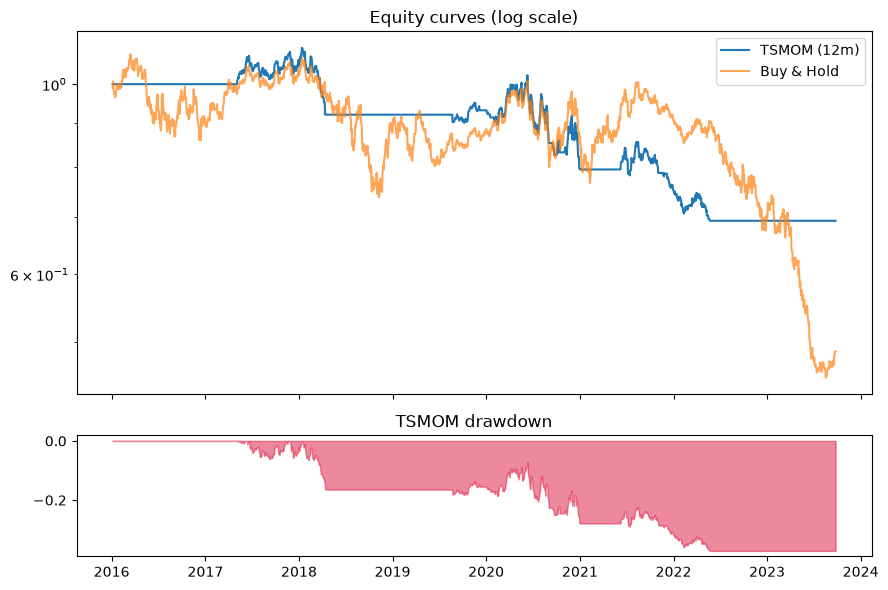

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1]})
ax1.plot(equity, label='TSMOM (12m)')
ax1.plot(bh_equity, label='Buy & Hold', alpha=0.7)
ax1.set_yscale('log'); ax1.legend(); ax1.set_title('Equity curves (log scale)')
dd = equity / equity.cummax() - 1
ax2.fill_between(dd.index, dd, 0, color='crimson', alpha=0.5)
ax2.set_title('TSMOM drawdown')
plt.tight_layout()
plt.show()

## Ideas to try with the AI reviewer

- Ask it to add **transaction costs** to the backtest and re-derive the Sharpe.
- Ask why `.shift(1)` matters (look-ahead bias) and what changes without it.
- Ask it to rewrite the momentum signal using `pandas-ta`, or to build a
  minimum-volatility portfolio with `PyPortfolioOpt` on a multi-asset version.